<a href="https://colab.research.google.com/github/Bur0mu/deep-learning-wildfire-unet/blob/main/notebooks/01_baseline_clasico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import os

USUARIO_GITHUB = "Bur0mu"
REPO_GITHUB = "https://github.com/Bur0mu/deep-learning-wildfire-unet.git"

# Clonar el repositorio en el entorno local de Colab
if not os.path.exists(REPO_GITHUB):
    !git clone https://github.com/Bur0mu/deep-learning-wildfire-unet.git

# Cambiar al directorio del proyecto
%cd {REPO_GITHUB}
print("Repositorio conectado correctamente. Carpeta actual:", os.getcwd())

fatal: destination path 'deep-learning-wildfire-unet' already exists and is not an empty directory.
[Errno 2] No such file or directory: 'https://github.com/Bur0mu/deep-learning-wildfire-unet.git'
/content
Repositorio conectado correctamente. Carpeta actual: /content


In [26]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Memoria:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("No se detectó GPU")


PyTorch: 2.14.1+cu130
CUDA disponible: True
GPU: Tesla T4
Memoria: 14.56 GB


In [27]:


!pip install -q rasterio geopandas shapely segmentation-models-pytorch opencv-python-headless kaggle tqdm

print("Librerías instaladas correctamente")



Librerías instaladas correctamente


In [28]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:

import os

BASE = "/content/drive/MyDrive/WildfireRisk_Maule"

folders = [
    "data/raw/crop_stress",
    "data/raw/plantvillage",
    "data/raw/wildfire_satellite",
    "data/raw/conaf",
    "data/raw/nasa",
    "data/processed/images",
    "data/processed/masks",
    "notebooks",
    "models",
    "results"
]

for folder in folders:
    os.makedirs(os.path.join(BASE, folder), exist_ok=True)

print("Proyecto creado correctamente")


Proyecto creado correctamente


In [30]:

from google.colab import userdata
import os

token = userdata.get("KAGGLE_API_TOKEN")

os.environ["KAGGLE_API_TOKEN"] = token

print("Kaggle configurado:", bool(token))


Kaggle configurado: True


In [31]:

!pip install -q --upgrade kaggle

!kaggle datasets list -s plantvillage


ref                                                       title                                              size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------  -------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
abdallahalidev/plantvillage-dataset                       PlantVillage Dataset                         4371949460  2019-09-01 11:52:26.883000         133234       1136  0.875            
emmarex/plantdisease                                      PlantVillage Dataset                          689512690  2018-10-30 01:16:23.440000         184256       1295  0.5625           
mohitsingh1804/plantvillage                               PlantVillage                                  857351099  2021-08-20 01:08:58.493000          21027        131  0.625            
soumiknafiul/plantvillage-dataset-labeled                 PlantVi

In [32]:

!kaggle datasets download \
-d datasetengineer/crop-health-and-environmental-stress-dataset \
-p /content/drive/MyDrive/WildfireRisk_Maule/data/raw/crop_stress \
--unzip


Dataset URL: https://www.kaggle.com/datasets/datasetengineer/crop-health-and-environmental-stress-dataset
License(s): CC-BY-NC-SA-4.0
100% 34.2M/34.2M [00:01<00:00, 21.0MB/s]



In [33]:

from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/WildfireRisk_Maule/data/raw/crop_stress"
)

files = [f for f in folder.rglob("*") if f.is_file()]

print("Total de archivos:", len(files))
print("\nPrimeros 30 archivos:")

for file in files[:30]:
    print(file.relative_to(folder))


Total de archivos: 1

Primeros 30 archivos:
agriculture_dataset.csv


In [34]:

import pandas as pd

csv_path = "/content/drive/MyDrive/WildfireRisk_Maule/data/raw/crop_stress/agriculture_dataset.csv"

df = pd.read_csv(csv_path)

print("DIMENSIONES DEL DATASET")
print(df.shape)

print("\nNOMBRES DE LAS COLUMNAS")
print(df.columns.tolist())

print("\nPRIMERAS 10 FILAS")
display(df.head(10))

print("\nINFORMACIÓN GENERAL")
df.info()

print("\nVALORES FALTANTES")
print(df.isnull().sum())


DIMENSIONES DEL DATASET
(212019, 32)

NOMBRES DE LAS COLUMNAS
['High_Resolution_RGB', 'Multispectral_Images', 'Thermal_Images', 'Temporal_Images', 'Spatial_Resolution', 'GPS_Coordinates', 'Field_Boundaries', 'Elevation_Data', 'Canopy_Coverage', 'NDVI', 'SAVI', 'Chlorophyll_Content', 'Leaf_Area_Index', 'Crop_Stress_Indicator', 'Temperature', 'Humidity', 'Rainfall', 'Wind_Speed', 'Soil_Moisture', 'Soil_pH', 'Organic_Matter', 'Pest_Hotspots', 'Weed_Coverage', 'Pest_Damage', 'Crop_Growth_Stage', 'Expected_Yield', 'Crop_Type', 'Ground_Truth_Segmentation', 'Bounding_Boxes', 'Water_Flow', 'Drainage_Features', 'Crop_Health_Label']

PRIMERAS 10 FILAS


,High_Resolution_RGB,Multispectral_Images,Thermal_Images,Temporal_Images,Spatial_Resolution,GPS_Coordinates,Field_Boundaries,Elevation_Data,Canopy_Coverage,NDVI,...,Weed_Coverage,Pest_Damage,Crop_Growth_Stage,Expected_Yield,Crop_Type,Ground_Truth_Segmentation,Bounding_Boxes,Water_Flow,Drainage_Features,Crop_Health_Label
0,0,0,0,0,0.667324,201538,3,28.207634,8.046926,0.676945,...,1.922274,84,2,2540.784327,Wheat,1,5,41.771884,0,1
1,1,1,0,0,1.459000,215854,3,82.335147,147.512332,0.414781,...,4.851381,56,3,3227.617025,Wheat,0,1,27.564635,0,1
2,0,0,0,0,0.500442,890802,3,83.865629,30.246527,0.723610,...,5.974859,38,1,4609.938146,Maize,1,8,29.510836,0,1
3,0,0,0,0,1.865161,605584,3,20.747905,6.857820,0.405611,...,2.100598,27,2,1409.716754,Maize,0,1,34.822855,0,0
4,0,1,1,1,1.392331,871732,3,22.588815,26.168558,0.465992,...,3.025669,84,4,3905.312588,Rice,0,2,15.493255,1,0
5,0,0,0,0,2.342274,251493,3,46.683234,29.525247,0.507520,...,4.426726,1,1,3186.428122,Wheat,0,6,41.304044,0,0
6,0,0,0,0,1.745272,665471,3,20.582658,22.422320,0.499019,...,0.892302,58,1,3096.231256,Wheat,0,9,3.313661,1,0
7,1,0,0,0,2.040050,899698,2,60.352718,76.419390,0.602585,...,4.115669,37,2,3759.071392,Wheat,0,6,29.300177,1,1
8,0,0,1,0,0.862034,300672,3,23.027399,3.294899,0.500893,...,1.884896,21,3,2492.937443,Wheat,1,4,18.688151,0,1
9,0,0,0,0,0.840869,452663,3,48.297885,299.805468,0.558419,...,4.406684,91,3,2660.762241,Wheat,0,7,23.678779,0,0



INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212019 entries, 0 to 212018
Data columns (total 32 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   High_Resolution_RGB        212019 non-null  int64  
 1   Multispectral_Images       212019 non-null  int64  
 2   Thermal_Images             212019 non-null  int64  
 3   Temporal_Images            212019 non-null  int64  
 4   Spatial_Resolution         212019 non-null  float64
 5   GPS_Coordinates            212019 non-null  int64  
 6   Field_Boundaries           212019 non-null  int64  
 7   Elevation_Data             212019 non-null  float64
 8   Canopy_Coverage            212019 non-null  float64
 9   NDVI                       212019 non-null  float64
 10  SAVI                       212019 non-null  float64
 11  Chlorophyll_Content        212019 non-null  float64
 12  Leaf_Area_Index            212019 non-null  float64
 13  Crop_Str

In [35]:

display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
High_Resolution_RGB,212019.0,0.200232,0.400175,0.000000e+00,0.000000,0.000000,0.000000,1.000000
Multispectral_Images,212019.0,0.299714,0.458134,0.000000e+00,0.000000,0.000000,1.000000,1.000000
Thermal_Images,212019.0,0.399492,0.489795,0.000000e+00,0.000000,0.000000,1.000000,1.000000
Temporal_Images,212019.0,0.100430,0.300573,0.000000e+00,0.000000,0.000000,0.000000,1.000000
Spatial_Resolution,212019.0,1.200244,0.499427,-9.597324e-01,0.862755,1.199967,1.538014,3.344946
GPS_Coordinates,212019.0,550433.748268,260335.476601,1.000030e+05,324279.000000,550668.000000,776122.000000,999986.000000
Field_Boundaries,212019.0,2.599946,0.663463,1.000000e+00,2.000000,3.000000,3.000000,3.000000
Elevation_Data,212019.0,54.948326,25.969531,1.000003e+01,32.550718,54.840251,77.443205,99.999944
Canopy_Coverage,212019.0,49.942370,49.925445,2.365532e-04,14.368852,34.544415,69.375661,582.456962
NDVI,212019.0,0.500288,0.149984,-1.652591e-01,0.398988,0.500420,0.600887,1.158040


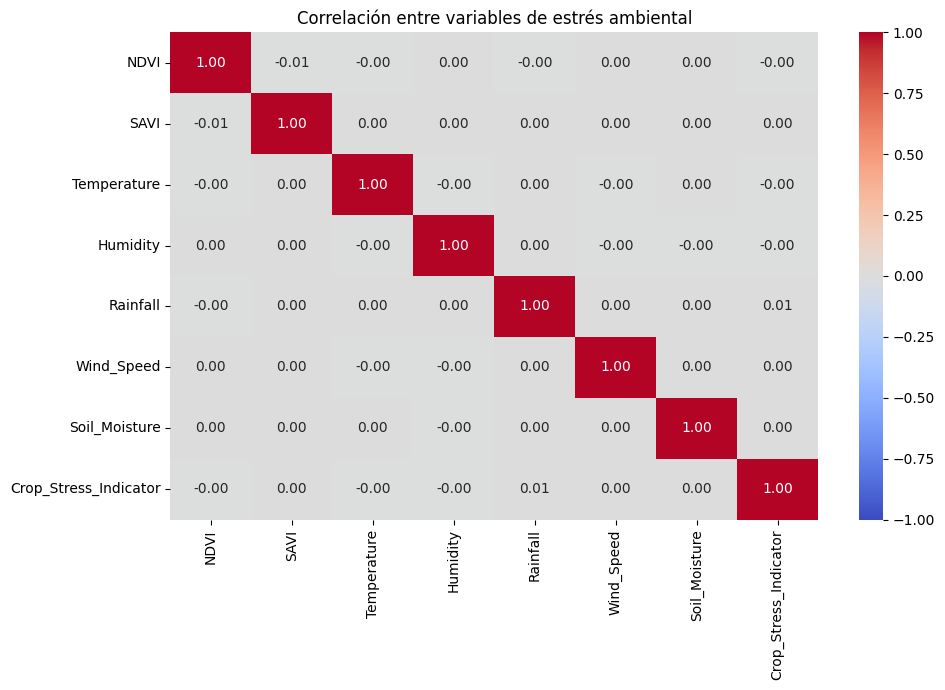

In [36]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

variables = [
    "NDVI",
    "SAVI",
    "Temperature",
    "Humidity",
    "Rainfall",
    "Wind_Speed",
    "Soil_Moisture",
    "Crop_Stress_Indicator"
]

corr = df[variables].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlación entre variables de estrés ambiental")
plt.tight_layout()
plt.show()


In [37]:

import os
import subprocess

BASE = "/content/drive/MyDrive/WildfireRisk_Maule"

destino = f"{BASE}/data/raw/wildfire_satellite/repository"

if not os.path.exists(destino):
    subprocess.run([
        "git",
        "clone",
        "https://github.com/doguilmak/Wildfire-Prediction-from-Satellite-Imagery.git",
        destino
    ], check=True)
else:
    print("El repositorio ya existe")

print("Proceso finalizado")



El repositorio ya existe
Proceso finalizado


In [38]:

from pathlib import Path
from collections import Counter

repo = Path(BASE) / "data/raw/wildfire_satellite/repository"

archivos = [p for p in repo.rglob("*") if p.is_file()]

print("Total de archivos:", len(archivos))

extensiones = Counter(
    p.suffix.lower() for p in archivos
)

print("\nTipos de archivos:")

for ext, cantidad in extensiones.most_common():
    print(ext or "[sin extensión]", cantidad)

print("\nPrimeros 30 archivos:")

for archivo in archivos[:30]:
    print(archivo.relative_to(repo))


Total de archivos: 53

Tipos de archivos:
.sample 14
[sin extensión] 12
.pb 6
.png 4
.ipynb 3
.py 2
.h5 2
.data-00000-of-00001 2
.index 2
.md 1
.psd 1
.csv 1
.pack 1
.rev 1
.idx 1

Primeros 30 archivos:
1_load_and_display_data.ipynb
2_pretrained_vgg16.ipynb
3_model_with_cam.ipynb
LICENSE
README.md
.git/description
.git/packed-refs
.git/HEAD
.git/config
.git/index
assets/wildfire_canada.png
assets/wildfire_canada.psd
model_plots/cam_model.png
model_plots/custom_model.png
model_plots/vgg_16_model.png
notebooks_as_py/1_load_and_display_data.py
notebooks_as_py/3_model_with_cam.py
predictions/custom_model_predictions.csv
saved_model/cam_model.h5
saved_model/custom_best_model.h5
saved_model/cam_model/fingerprint.pb
saved_model/cam_model/keras_metadata.pb
saved_model/cam_model/saved_model.pb
saved_model/custom_model/fingerprint.pb
saved_model/custom_model/keras_metadata.pb
saved_model/custom_model/saved_model.pb
saved_model/custom_model/variables/variables.data-00000-of-00001
saved_model/cust

In [39]:

import geopandas as gpd
import requests
from pathlib import Path

BASE = "/content/drive/MyDrive/WildfireRisk_Maule"

# URL corregida de la Región del Maule
url = (
    "https://raw.githubusercontent.com/"
    "caracena/chile-geojson/master/7.geojson"
)

# Carpeta de destino
destino = Path(BASE) / "data/raw/conaf/maule.geojson"
destino.parent.mkdir(parents=True, exist_ok=True)

# Descargar archivo
respuesta = requests.get(url, timeout=60)
respuesta.raise_for_status()

destino.write_bytes(respuesta.content)

# Leer GeoJSON
maule = gpd.read_file(destino)

print("Archivo descargado correctamente")
print("Geometrías:", len(maule))
print("CRS:", maule.crs)
print("Extensión:", maule.total_bounds)
print("Columnas:", maule.columns.tolist())


Archivo descargado correctamente
Geometrías: 30
CRS: EPSG:4326
Extensión: [-72.7859005  -36.54356466 -70.31257993 -34.68473636]
Columnas: ['objectid', 'shape_leng', 'dis_elec', 'cir_sena', 'cod_comuna', 'codregion', 'st_area_sh', 'st_length_', 'Region', 'Comuna', 'Provincia', 'geometry']


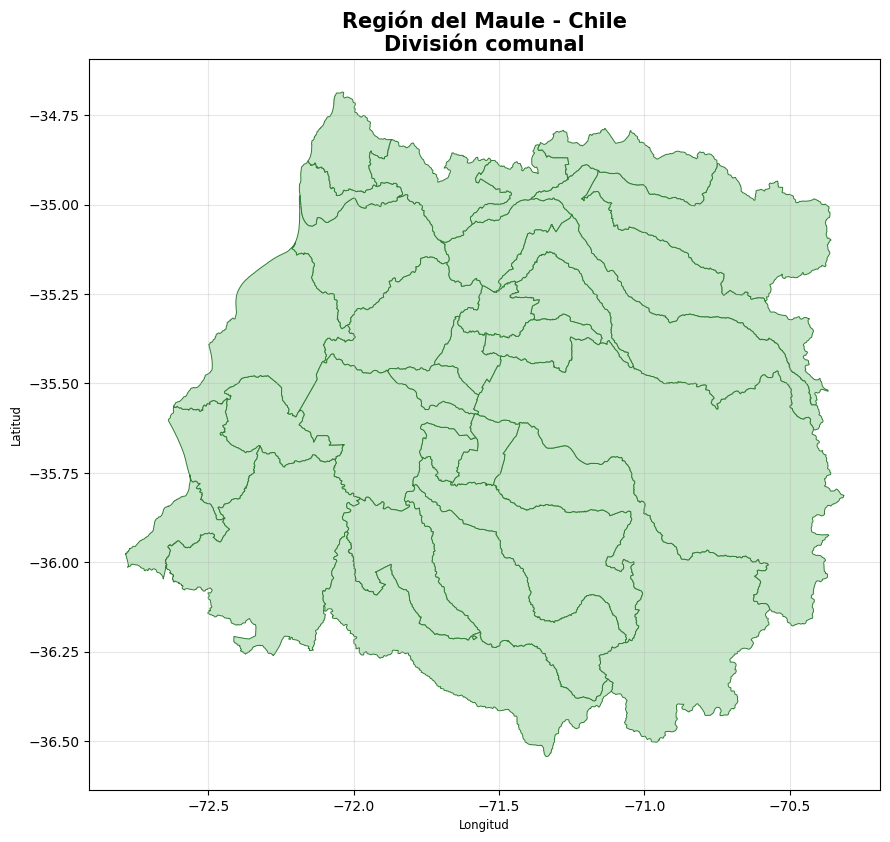

In [40]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 10))

maule.plot(
    ax=ax,
    color="#C8E6C9",
    edgecolor="#2E7D32",
    linewidth=0.7
)

ax.set_title(
    "Región del Maule - Chile\nDivisión comunal",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [41]:

!pip install -q earthengine-api geemap

import ee
import geemap

print("Google Earth Engine instalado correctamente")


Google Earth Engine instalado correctamente


In [42]:

import ee

ee.Authenticate()

print("Autenticación completada")


Autenticación completada


In [43]:

import ee

# Reemplaza con tu ID real de Google Cloud
PROJECT_ID = "881748607997"

ee.Initialize(project=PROJECT_ID)

print("Earth Engine inicializado correctamente")

# Verificar acceso a los datos
imagen = ee.Image("USGS/SRTMGL1_003")

print("Bandas disponibles:")
print(imagen.bandNames().getInfo())


Earth Engine inicializado correctamente
Bandas disponibles:
['elevation']


In [44]:

import ee

# Zona piloto alrededor de Talca
zona_piloto = ee.Geometry.Rectangle([
    -71.85, -35.60,
    -71.45, -35.25
])

# Imágenes Sentinel-2 de verano
sentinel = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(zona_piloto)
    .filterDate("2025-01-01", "2025-03-01")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
)

print("Cantidad de imágenes encontradas:")
print(sentinel.size().getInfo())

print("\nFechas de las primeras imágenes:")

fechas = sentinel.aggregate_array(
    "system:time_start"
).getInfo()

from datetime import datetime, timezone

for fecha in fechas[:10]:
    print(
        datetime.fromtimestamp(
            fecha / 1000,
            tz=timezone.utc
        ).strftime("%Y-%m-%d")
    )


Cantidad de imágenes encontradas:
43

Fechas de las primeras imágenes:
2025-01-02
2025-01-02
2025-01-02
2025-01-02
2025-01-12
2025-01-12
2025-01-12
2025-01-17
2025-01-17
2025-01-22


In [45]:

import ee
import geemap

# Enmascarar nubes y sombras usando la banda SCL
def limpiar_nubes(imagen):
    scl = imagen.select("SCL")

    mascara = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return imagen.updateMask(mascara)

# Aplicar máscara de nubes
sentinel_limpio = sentinel.map(limpiar_nubes)

# Crear mosaico con mediana temporal
mosaico = (
    sentinel_limpio
    .median()
    .clip(zona_piloto)
)

print("Mosaico Sentinel-2 preparado correctamente")


Mosaico Sentinel-2 preparado correctamente


In [46]:

import ee
import geemap

# Unir las 30 comunas en una geometría regional
maule_union = maule.to_crs("EPSG:4326").geometry.union_all()

# Convertir geometría a Earth Engine
zona_maule = ee.Geometry(
    maule_union.__geo_interface__
)

print("Región del Maule cargada correctamente")
print("Área de estudio ampliada")


Región del Maule cargada correctamente
Área de estudio ampliada


In [47]:

sentinel_maule = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(zona_maule)
    .filterDate("2025-01-01", "2025-03-01")
    .filter(
        ee.Filter.lt(
            "CLOUDY_PIXEL_PERCENTAGE", 20
        )
    )
)

print(
    "Imágenes encontradas:",
    sentinel_maule.size().getInfo()
)

mosaico_maule = (
    sentinel_maule
    .map(limpiar_nubes)
    .median()
    .clip(zona_maule)
)

print("Mosaico regional preparado")


Imágenes encontradas: 168
Mosaico regional preparado


In [48]:

mapa_maule = geemap.Map(
    basemap="Esri.WorldImagery"
)

mapa_maule.centerObject(zona_maule, 8)

mapa_maule.addLayer(
    mosaico_maule,
    {
        "bands": ["B4", "B3", "B2"],
        "min": 0,
        "max": 3000,
        "gamma": 1.2
    },
    "Sentinel-2 - Región del Maule"
)

mapa_maule


Map(center=[-35.620438392409, -71.44546194248232], controls=(WidgetControl(options=['position', 'transparent_b…

In [49]:

ndvi_maule = mosaico_maule.normalizedDifference(
    ["B8", "B4"]
).rename("NDVI")

ndmi_maule = mosaico_maule.normalizedDifference(
    ["B8", "B11"]
).rename("NDMI")

print("NDVI y NDMI regionales preparados")


NDVI y NDMI regionales preparados


In [50]:

import ee
import geemap

# Convertir las comunas a Earth Engine
comunas_ee = geemap.geopandas_to_ee(maule)

# Dibujar contorno regional
contorno_region = ee.Image().byte().paint(
    featureCollection=ee.FeatureCollection([
        ee.Feature(zona_maule)
    ]),
    color=1,
    width=3
)

# Dibujar límites comunales
limites_comunas = ee.Image().byte().paint(
    featureCollection=comunas_ee,
    color=1,
    width=1
)

# Crear mapa
mapa_completo = geemap.Map(
    basemap="Esri.WorldImagery"
)

mapa_completo.centerObject(zona_maule, 8)

mapa_completo.addLayer(
    mosaico_maule,
    {
        "bands": ["B4", "B3", "B2"],
        "min": 0,
        "max": 3000,
        "gamma": 1.2
    },
    "Sentinel-2 Maule"
)

mapa_completo.addLayer(
    limites_comunas,
    {"palette": ["yellow"]},
    "Límites comunales"
)

mapa_completo.addLayer(
    contorno_region,
    {"palette": ["red"]},
    "Límite Región del Maule"
)

mapa_completo


Map(center=[-35.620438392409, -71.44546194248232], controls=(WidgetControl(options=['position', 'transparent_b…

In [51]:

# Calcular NDVI regional
ndvi_maule = mosaico_maule.normalizedDifference(
    ["B8", "B4"]
).rename("NDVI")

# Calcular NDMI regional
ndmi_maule = mosaico_maule.normalizedDifference(
    ["B8", "B11"]
).rename("NDMI")

print("NDVI regional calculado")
print("NDMI regional calculado")


NDVI regional calculado
NDMI regional calculado


In [52]:

import geemap

mapa_indices_maule = geemap.Map(
    basemap="Esri.WorldImagery"
)

mapa_indices_maule.centerObject(zona_maule, 8)

vis_ndvi = {
    "min": -0.2,
    "max": 0.8,
    "palette": [
        "brown", "yellow", "lightgreen",
        "green", "darkgreen"
    ]
}

vis_ndmi = {
    "min": -0.5,
    "max": 0.5,
    "palette": [
        "red", "orange", "yellow",
        "lightblue", "blue"
    ]
}

mapa_indices_maule.addLayer(
    ndvi_maule,
    vis_ndvi,
    "NDVI - Región del Maule"
)

mapa_indices_maule.addLayer(
    ndmi_maule,
    vis_ndmi,
    "NDMI - Región del Maule",
    False
)

mapa_indices_maule.addLayer(
    contorno_region,
    {"palette": ["red"]},
    "Límite regional"
)

mapa_indices_maule.addLayer(
    limites_comunas,
    {"palette": ["yellow"]},
    "Límites comunales",
    False
)

mapa_indices_maule


Map(center=[-35.620438392409, -71.44546194248232], controls=(WidgetControl(options=['position', 'transparent_b…

In [53]:

# Combinar ambos índices
indices_maule = ndvi_maule.addBands(ndmi_maule)

# Calcular estadísticas a escala regional
estadisticas = indices_maule.reduceRegion(
    reducer=ee.Reducer.minMax().combine(
        reducer2=ee.Reducer.mean(),
        sharedInputs=True
    ),
    geometry=zona_maule,
    scale=100,
    maxPixels=1e9,
    bestEffort=True,
    tileScale=4
)

print("ESTADÍSTICAS NDVI Y NDMI")
print("-------------------------")

resultados = estadisticas.getInfo()

for variable, valor in resultados.items():
    print(f"{variable}: {valor:.4f}")


ESTADÍSTICAS NDVI Y NDMI
-------------------------
NDMI_max: 0.9528
NDMI_mean: 0.1354
NDMI_min: -1.0000
NDVI_max: 1.0000
NDVI_mean: 0.4698
NDVI_min: -1.0000


In [58]:
import ee

# Usar los índices de la zona piloto (corregido a las variables regionales)
indices_piloto = (
    ndvi_maule.addBands(ndmi_maule)
    .toFloat()
    .clip(zona_piloto)
)

# Crear exportación a Google Drive
tarea = ee.batch.Export.image.toDrive(
    image=indices_piloto,
    description="NDVI_NDMI_Talca_2025",
    folder="WildfireRisk_Exports",
    fileNamePrefix="ndvi_ndmi_talca_2025",
    region=zona_piloto,
    scale=20,
    maxPixels=1e9,
    fileFormat="GeoTIFF"
)

tarea.start()

print("Exportación iniciada")
print("ID de tarea:", tarea.id)
print("Estado:", tarea.status()["state"])


Exportación iniciada
ID de tarea: ESSFVEN5HLTJV3AWB6XWYNZF
Estado: READY


In [59]:

estado = tarea.status()

print("Estado:", estado["state"])

if estado["state"] == "COMPLETED":
    print("Archivo exportado correctamente a Google Drive")
elif estado["state"] == "FAILED":
    print("Error:", estado.get("error_message", "Sin detalle"))
else:
    print("La tarea todavía está en proceso")


Estado: READY
La tarea todavía está en proceso


In [60]:

import rasterio
import numpy as np
from pathlib import Path

# Ruta del archivo exportado
ruta_tif = Path(
    "/content/drive/MyDrive/WildfireRisk_Exports/"
    "ndvi_ndmi_talca_2025.tif"
)

print("Archivo encontrado:", ruta_tif.exists())

if ruta_tif.exists():
    with rasterio.open(ruta_tif) as src:
        print("\nINFORMACIÓN DEL GEOTIFF")
        print("Ancho:", src.width)
        print("Alto:", src.height)
        print("Número de bandas:", src.count)
        print("CRS:", src.crs)
        print("Resolución:", src.res)
        print("Tipo de datos:", src.dtypes)
        print("NoData:", src.nodata)

        for i, nombre in enumerate(
            ["NDVI", "NDMI"], start=1
        ):
            banda = src.read(i, masked=True)
            valores = banda.compressed()

            print(f"\n{nombre}")
            print("Mínimo:", valores.min())
            print("Máximo:", valores.max())
            print("Promedio:", valores.mean())
else:
    print("No se encontró el archivo en esa ruta.")
    print("Revisa la carpeta WildfireRisk_Exports.")


Archivo encontrado: True

INFORMACIÓN DEL GEOTIFF
Ancho: 2228
Alto: 1950
Número de bandas: 2
CRS: EPSG:4326
Resolución: (0.0001796630568239043, 0.0001796630568239043)
Tipo de datos: ('float32', 'float32')
NoData: None

NDVI
Mínimo: nan
Máximo: nan
Promedio: nan

NDMI
Mínimo: nan
Máximo: nan
Promedio: nan


In [61]:

import rasterio
import numpy as np

with rasterio.open(ruta_tif) as src:

    print("ANÁLISIS DE VALORES VÁLIDOS")
    print("--------------------------")

    for i, nombre in enumerate(
        ["NDVI", "NDMI"], start=1
    ):
        banda = src.read(i)

        # Identificar valores numéricos válidos
        validos = np.isfinite(banda)

        total = banda.size
        cantidad_validos = np.count_nonzero(validos)
        cantidad_invalidos = total - cantidad_validos

        print(f"\n{nombre}")
        print("Total de píxeles:", total)
        print("Píxeles válidos:", cantidad_validos)
        print("Píxeles inválidos:", cantidad_invalidos)

        porcentaje = 100 * cantidad_validos / total
        print(f"Porcentaje válido: {porcentaje:.2f}%")

        if cantidad_validos > 0:
            valores = banda[validos]

            print("Mínimo:", valores.min())
            print("Máximo:", valores.max())
            print("Promedio:", valores.mean())
        else:
            print("No se encontraron valores válidos")


ANÁLISIS DE VALORES VÁLIDOS
--------------------------

NDVI
Total de píxeles: 4344600
Píxeles válidos: 4342295
Píxeles inválidos: 2305
Porcentaje válido: 99.95%
Mínimo: -0.7249284
Máximo: 0.9542025
Promedio: 0.4808185

NDMI
Total de píxeles: 4344600
Píxeles válidos: 4342295
Píxeles inválidos: 2305
Porcentaje válido: 99.95%
Mínimo: -0.7699115
Máximo: 0.8325826
Promedio: 0.11513402


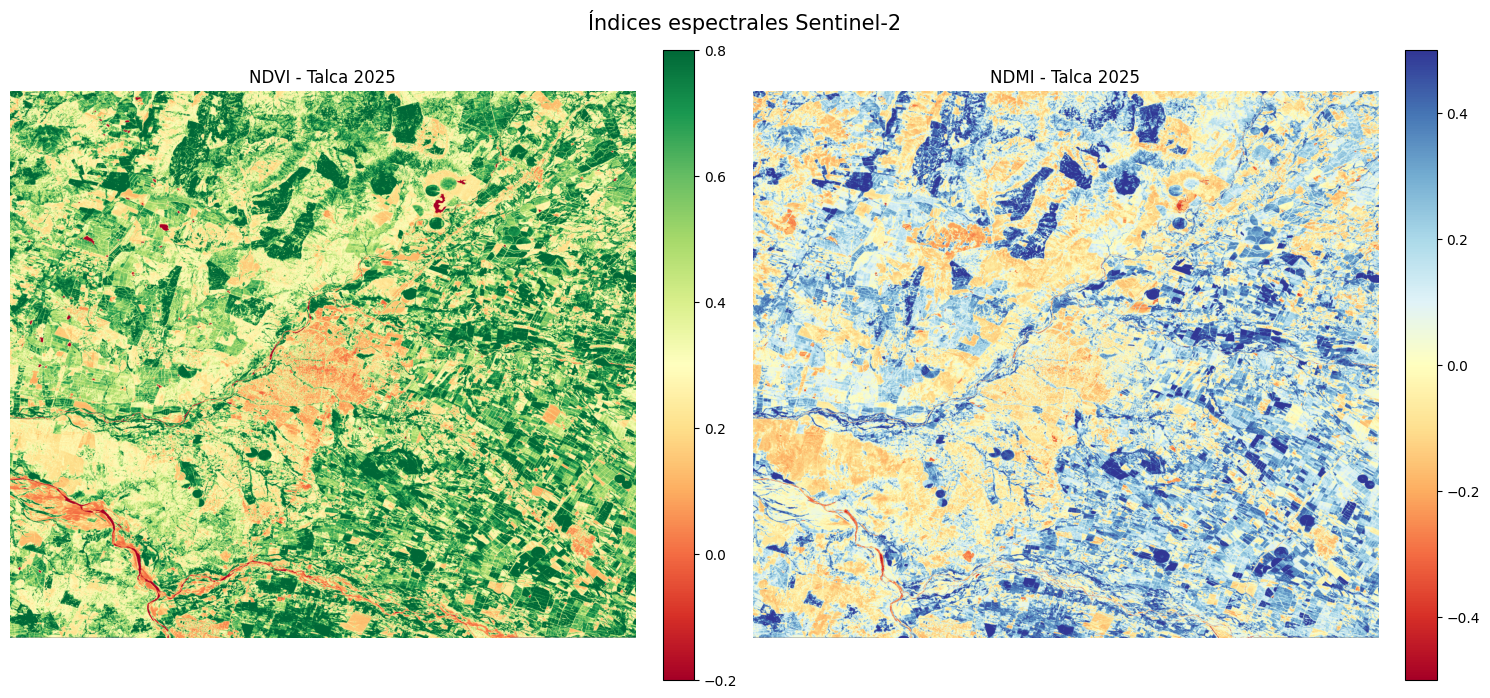

In [62]:

import rasterio
import numpy as np
import matplotlib.pyplot as plt

with rasterio.open(ruta_tif) as src:
    ndvi_array = src.read(1)
    ndmi_array = src.read(2)

# Ocultar los píxeles inválidos
ndvi_array = np.ma.masked_invalid(ndvi_array)
ndmi_array = np.ma.masked_invalid(ndmi_array)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# NDVI
im1 = axes[0].imshow(
    ndvi_array,
    cmap="RdYlGn",
    vmin=-0.2,
    vmax=0.8
)

axes[0].set_title("NDVI - Talca 2025")
axes[0].axis("off")

fig.colorbar(
    im1,
    ax=axes[0],
    fraction=0.046,
    pad=0.04
)

# NDMI
im2 = axes[1].imshow(
    ndmi_array,
    cmap="RdYlBu",
    vmin=-0.5,
    vmax=0.5
)

axes[1].set_title("NDMI - Talca 2025")
axes[1].axis("off")

fig.colorbar(
    im2,
    ax=axes[1],
    fraction=0.046,
    pad=0.04
)

plt.suptitle(
    "Índices espectrales Sentinel-2",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [63]:

import rasterio
from rasterio.warp import calculate_default_transform

with rasterio.open(ruta_tif) as src:

    transform, width, height = calculate_default_transform(
        src.crs,
        "EPSG:32719",
        src.width,
        src.height,
        *src.bounds
    )

    print("CRS original:", src.crs)
    print("CRS proyectado: EPSG:32719")

    print("\nDimensiones proyectadas:")
    print("Ancho:", width)
    print("Alto:", height)

    print("\nTamaño estimado de píxel:")
    print("X:", abs(transform.a), "metros")
    print("Y:", abs(transform.e), "metros")


CRS original: EPSG:4326
CRS proyectado: EPSG:32719

Dimensiones proyectadas:
Ancho: 2080
Alto: 2216

Tamaño estimado de píxel:
X: 17.980197203461213 metros
Y: 17.980197203461213 metros


In [64]:

import rasterio
from rasterio.warp import (
    calculate_default_transform,
    reproject,
    Resampling
)
from rasterio.transform import from_origin
from pathlib import Path
import numpy as np
import math

salida = Path(
    "/content/drive/MyDrive/WildfireRisk_Maule/"
    "data/processed/ndvi_ndmi_talca_utm19s.tif"
)

salida.parent.mkdir(parents=True, exist_ok=True)

with rasterio.open(ruta_tif) as src:

    # Calcular extensión aproximada en UTM
    transform_base, _, _ = calculate_default_transform(
        src.crs,
        "EPSG:32719",
        src.width,
        src.height,
        *src.bounds
    )

    # Obtener extensión proyectada
    from rasterio.warp import transform_bounds

    xmin, ymin, xmax, ymax = transform_bounds(
        src.crs,
        "EPSG:32719",
        *src.bounds
    )

    # Cuadrícula de 20 metros
    resolucion = 20

    ancho = math.ceil((xmax - xmin) / resolucion)
    alto = math.ceil((ymax - ymin) / resolucion)

    transform = from_origin(
        xmin,
        ymax,
        resolucion,
        resolucion
    )

    perfil = src.profile.copy()
    perfil.update(
        crs="EPSG:32719",
        transform=transform,
        width=ancho,
        height=alto,
        dtype="float32",
        nodata=np.nan,
        compress="deflate"
    )

    with rasterio.open(salida, "w", **perfil) as dst:

        for banda in range(1, src.count + 1):
            reproject(
                source=rasterio.band(src, banda),
                destination=rasterio.band(dst, banda),
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=np.nan,
                dst_transform=transform,
                dst_crs="EPSG:32719",
                dst_nodata=np.nan,
                resampling=Resampling.bilinear
            )

print("Reproyección completada")
print("Archivo:", salida)

with rasterio.open(salida) as src:
    print("CRS:", src.crs)
    print("Resolución:", src.res)
    print("Dimensiones:", src.width, "x", src.height)
    print("Bandas:", src.count)


Reproyección completada
Archivo: /content/drive/MyDrive/WildfireRisk_Maule/data/processed/ndvi_ndmi_talca_utm19s.tif
CRS: EPSG:32719
Resolución: (20.0, 20.0)
Dimensiones: 1870 x 1993
Bandas: 2


In [65]:

import rasterio
import numpy as np

with rasterio.open(salida) as src:

    print("VALIDACIÓN DEL ARCHIVO REPROYECTADO")
    print("----------------------------------")

    print("CRS:", src.crs)
    print("Resolución:", src.res)
    print("Bandas:", src.count)

    for i, nombre in enumerate(["NDVI", "NDMI"], 1):

        datos = src.read(i)
        validos = np.isfinite(datos)

        total = datos.size
        cantidad = np.count_nonzero(validos)

        print(f"\n{nombre}")
        print("Píxeles válidos:", cantidad)
        print(
            "Porcentaje válido:",
            round(100 * cantidad / total, 2), "%"
        )

        if cantidad > 0:
            valores = datos[validos]

            print("Mínimo:", valores.min())
            print("Máximo:", valores.max())
            print("Promedio:", valores.mean())

            fuera_rango = np.count_nonzero(
                (valores < -1) | (valores > 1)
            )

            print("Valores fuera de [-1, 1]:", fuera_rango)


VALIDACIÓN DEL ARCHIVO REPROYECTADO
----------------------------------
CRS: EPSG:32719
Resolución: (20.0, 20.0)
Bandas: 2

NDVI
Píxeles válidos: 3532857
Porcentaje válido: 94.79 %
Mínimo: -0.6832627
Máximo: 0.94904566
Promedio: 0.4808306
Valores fuera de [-1, 1]: 0

NDMI
Píxeles válidos: 3532857
Porcentaje válido: 94.79 %
Mínimo: -0.6355743
Máximo: 0.7535309
Promedio: 0.115120396
Valores fuera de [-1, 1]: 0


In [66]:

import rasterio
import numpy as np
from pathlib import Path
from rasterio.windows import Window
from rasterio.windows import transform as window_transform

# Carpeta de salida
carpeta_tiles = Path(
    "/content/drive/MyDrive/WildfireRisk_Maule/"
    "data/processed/images"
)

carpeta_tiles.mkdir(parents=True, exist_ok=True)

tamano = 256
contador = 0
descartados = 0

with rasterio.open(salida) as src:

    for fila in range(0, src.height, tamano):
        for columna in range(0, src.width, tamano):

            # Evitar fragmentos incompletos
            if (
                fila + tamano > src.height
                or columna + tamano > src.width
            ):
                continue

            ventana = Window(
                columna, fila, tamano, tamano
            )

            datos = src.read(window=ventana)

            # Píxeles válidos en ambos canales
            validos = np.isfinite(datos).all(axis=0)

            porcentaje = validos.mean()

            # Conservar tiles con al menos 95% válido
            if porcentaje < 0.95:
                descartados += 1
                continue

            # Mantener NaN para no inventar datos
            perfil = src.profile.copy()
            perfil.update(
                width=tamano,
                height=tamano,
                transform=window_transform(
                    ventana, src.transform
                ),
                nodata=np.nan
            )

            nombre = (
                f"tile_{fila:04d}_{columna:04d}.tif"
            )

            ruta_tile = carpeta_tiles / nombre

            with rasterio.open(
                ruta_tile, "w", **perfil
            ) as dst:
                dst.write(datos)

            contador += 1

print("PROCESAMIENTO FINALIZADO")
print("Tiles guardados:", contador)
print("Tiles descartados:", descartados)
print("Carpeta:", carpeta_tiles)


PROCESAMIENTO FINALIZADO
Tiles guardados: 39
Tiles descartados: 10
Carpeta: /content/drive/MyDrive/WildfireRisk_Maule/data/processed/images


Total de archivos: 39
Archivo: tile_0000_1280.tif
Dimensiones: (2, 256, 256)
CRS: EPSG:32719
Resolución: (20.0, 20.0)


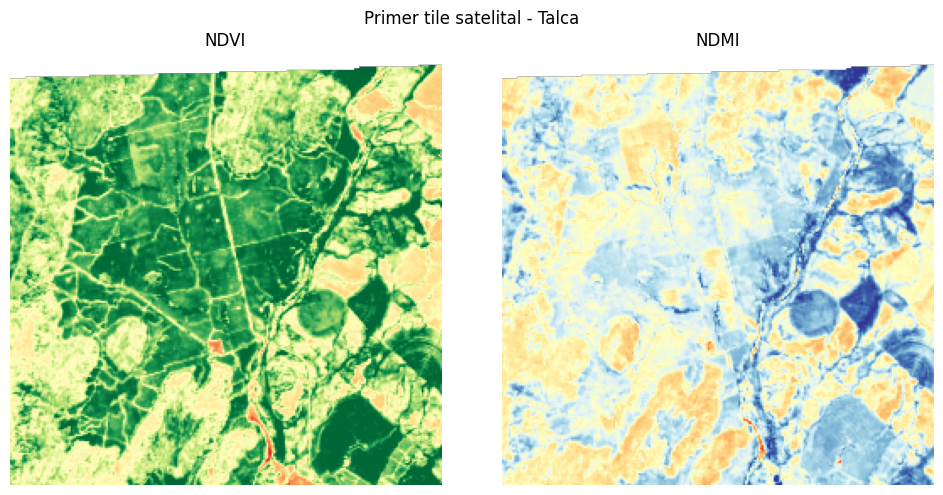

In [67]:

import rasterio
import numpy as np
import matplotlib.pyplot as plt

archivos_tiles = sorted(carpeta_tiles.glob("*.tif"))

print("Total de archivos:", len(archivos_tiles))

# Seleccionar el primer fragmento
archivo = archivos_tiles[0]

with rasterio.open(archivo) as src:
    datos = src.read()
    print("Archivo:", archivo.name)
    print("Dimensiones:", datos.shape)
    print("CRS:", src.crs)
    print("Resolución:", src.res)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(
    np.ma.masked_invalid(datos[0]),
    cmap="RdYlGn",
    vmin=-0.2,
    vmax=0.8
)
axes[0].set_title("NDVI")

axes[1].imshow(
    np.ma.masked_invalid(datos[1]),
    cmap="RdYlBu",
    vmin=-0.5,
    vmax=0.5
)
axes[1].set_title("NDMI")

for ax in axes:
    ax.axis("off")

plt.suptitle("Primer tile satelital - Talca")
plt.tight_layout()
plt.show()
